# Detector clock alignment

This notebook fits a **candidate relative clock correction** for three detectors.
It estimates shared timing peaks in separate windows throughout the recording, then fits an
offset and constant clock drift using training windows only. Other windows assess the fit.

Choose `ground_run_01` or `2026-05-31` below. Each run gets its own clock fit and reference.
This is separate from the radiation-profile GAM.
Raw files, event IDs, coincidence flags, amplitudes, and deadtime are preserved. The logger's
recording coverage remains unresolved and the logger is not aligned here.

In [1]:
from pathlib import Path
import importlib
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Image

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "src" / "align_clocks.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Extract this package into the repository so src/align_clocks.py exists.")
sys.path.insert(0, str(ROOT / "src"))
import align_clocks
importlib.reload(align_clocks)
print("Repository:", ROOT)

Repository: C:\Users\gunja\Documents\Hera\HERA-Machine-Learning


In [2]:
RUN_ID = "2026-05-31"  # Or "2026-05-31". Coefficients are always refitted.
if RUN_ID == "ground_run_01":
    DATA_DIR = ROOT / "raw" / RUN_ID
    DETECTOR_FILES = {name: DATA_DIR / f"{name}.txt" for name in ["top", "mid", "bot"]}
    REFERENCE_ID = "top"
    LOGGER_FILE = DATA_DIR / "AHD038.csv"
    TRAIN_CENTERS_HOURS = np.arange(0.5, 193.0, 12.0)
    VALIDATION_CENTERS_HOURS = np.arange(6.5, 193.0, 12.0)
    WINDOW_SECONDS = 600.0
elif RUN_ID == "2026-05-31":
    def resolve_source(value):
        path = Path(value)
        return (path if path.is_absolute() else ROOT / path).resolve()
    configurations = {}
    for device in ["left", "middle", "right"]:
        cfg_path = ROOT / "configs" / f"{RUN_ID}_{device}.json"
        cfg = json.loads(cfg_path.read_text(encoding="utf-8"))
        if (cfg["flight_id"], cfg["detector_id"]) != (RUN_ID, device):
            raise ValueError(f"Configuration identity mismatch: {cfg_path}")
        configurations[device] = cfg
    DETECTOR_FILES = {name: resolve_source(cfg["detector_file"])
                      for name,cfg in configurations.items()}
    logger_paths = {resolve_source(cfg["logger_file"]) for cfg in configurations.values()}
    if len(logger_paths) != 1:
        raise ValueError("May 31 configurations reference different logger files.")
    LOGGER_FILE = logger_paths.pop()
    REFERENCE_ID = "left"
    TRAIN_CENTERS_HOURS = np.arange(0.5, 11.0, 2.0)
    VALIDATION_CENTERS_HOURS = np.arange(1.5, 12.0, 2.0)
    WINDOW_SECONDS = 1200.0  # More events for the low-rate parts of this recording.
else:
    raise ValueError("Review input paths and window settings before adding another run.")

SEARCH_SECONDS = 120.0
CORRELATION_BIN_SECONDS = 0.01

for path in [*DETECTOR_FILES.values(), LOGGER_FILE]:
    if not path.is_file():
        raise FileNotFoundError(path)
display(pd.DataFrame([{"device":name,"file":str(path)}
                      for name,path in {**DETECTOR_FILES,"logger":LOGGER_FILE}.items()]))

,device,file
0,left,C:\Users\gunja\Documents\Hera\HERA-Machine-Lea...
1,middle,C:\Users\gunja\Documents\Hera\HERA-Machine-Lea...
2,right,C:\Users\gunja\Documents\Hera\HERA-Machine-Lea...
3,logger,C:\Users\gunja\Documents\Hera\HERA-Machine-Lea...


## Fit and assess the clock map

Ground: 17 fitting and 16 validation windows, each 600 seconds long.
May 31: six fitting and six validation windows, each 1200 seconds long.
The lag search extends 120 seconds in either direction. Windows and search margins
must not overlap. All-event timestamps are used; the zero coincidence flags supply no labels.

The map is `other_time = offset + (1 + drift) * reference_time`.
For a candidate corrected timestamp, invert this equation. The validation score measures
the error in a locally estimated timing peak, **not** particle-matching accuracy or UTC accuracy.

In [3]:
report, local_lags, RUN_DIR = align_clocks.run(
    ROOT, DETECTOR_FILES, REFERENCE_ID, RUN_ID,
    TRAIN_CENTERS_HOURS * 3600,
    VALIDATION_CENTERS_HOURS * 3600,
    logger_file=LOGGER_FILE,
    window_s=WINDOW_SECONDS,
    search_s=SEARCH_SECONDS,
    bin_s=CORRELATION_BIN_SECONDS,
)
print("Outputs:", RUN_DIR)
display(pd.DataFrame([{"device":device, **metrics}
                      for device,metrics in report["metrics"].items()]))
display(local_lags.groupby(["device","split"])["timing_signal_supported"].agg(["sum","count"]))
print("Source files unchanged:", report["source_hashes_unchanged"])

Outputs: C:\Users\gunja\Documents\Hera\HERA-Machine-Learning\results\2026-05-31\20261116T060758899275Z_clock_alignment


,device,training_windows,validation_windows,supported_validation_windows,constant_offset_validation_mae_ms,affine_validation_mae_ms,affine_validation_max_abs_error_ms,metric_definition
0,middle,6,6,6,36.753904,3.168848,9.730498,Error in locally estimated lag at held-out win...
1,right,6,6,6,8.292522,4.071328,12.946173,Error in locally estimated lag at held-out win...


sum  count
device split                 
middle train         6      6
       validation    6      6
right  train         6      6
       validation    6      6

Source files unchanged: True


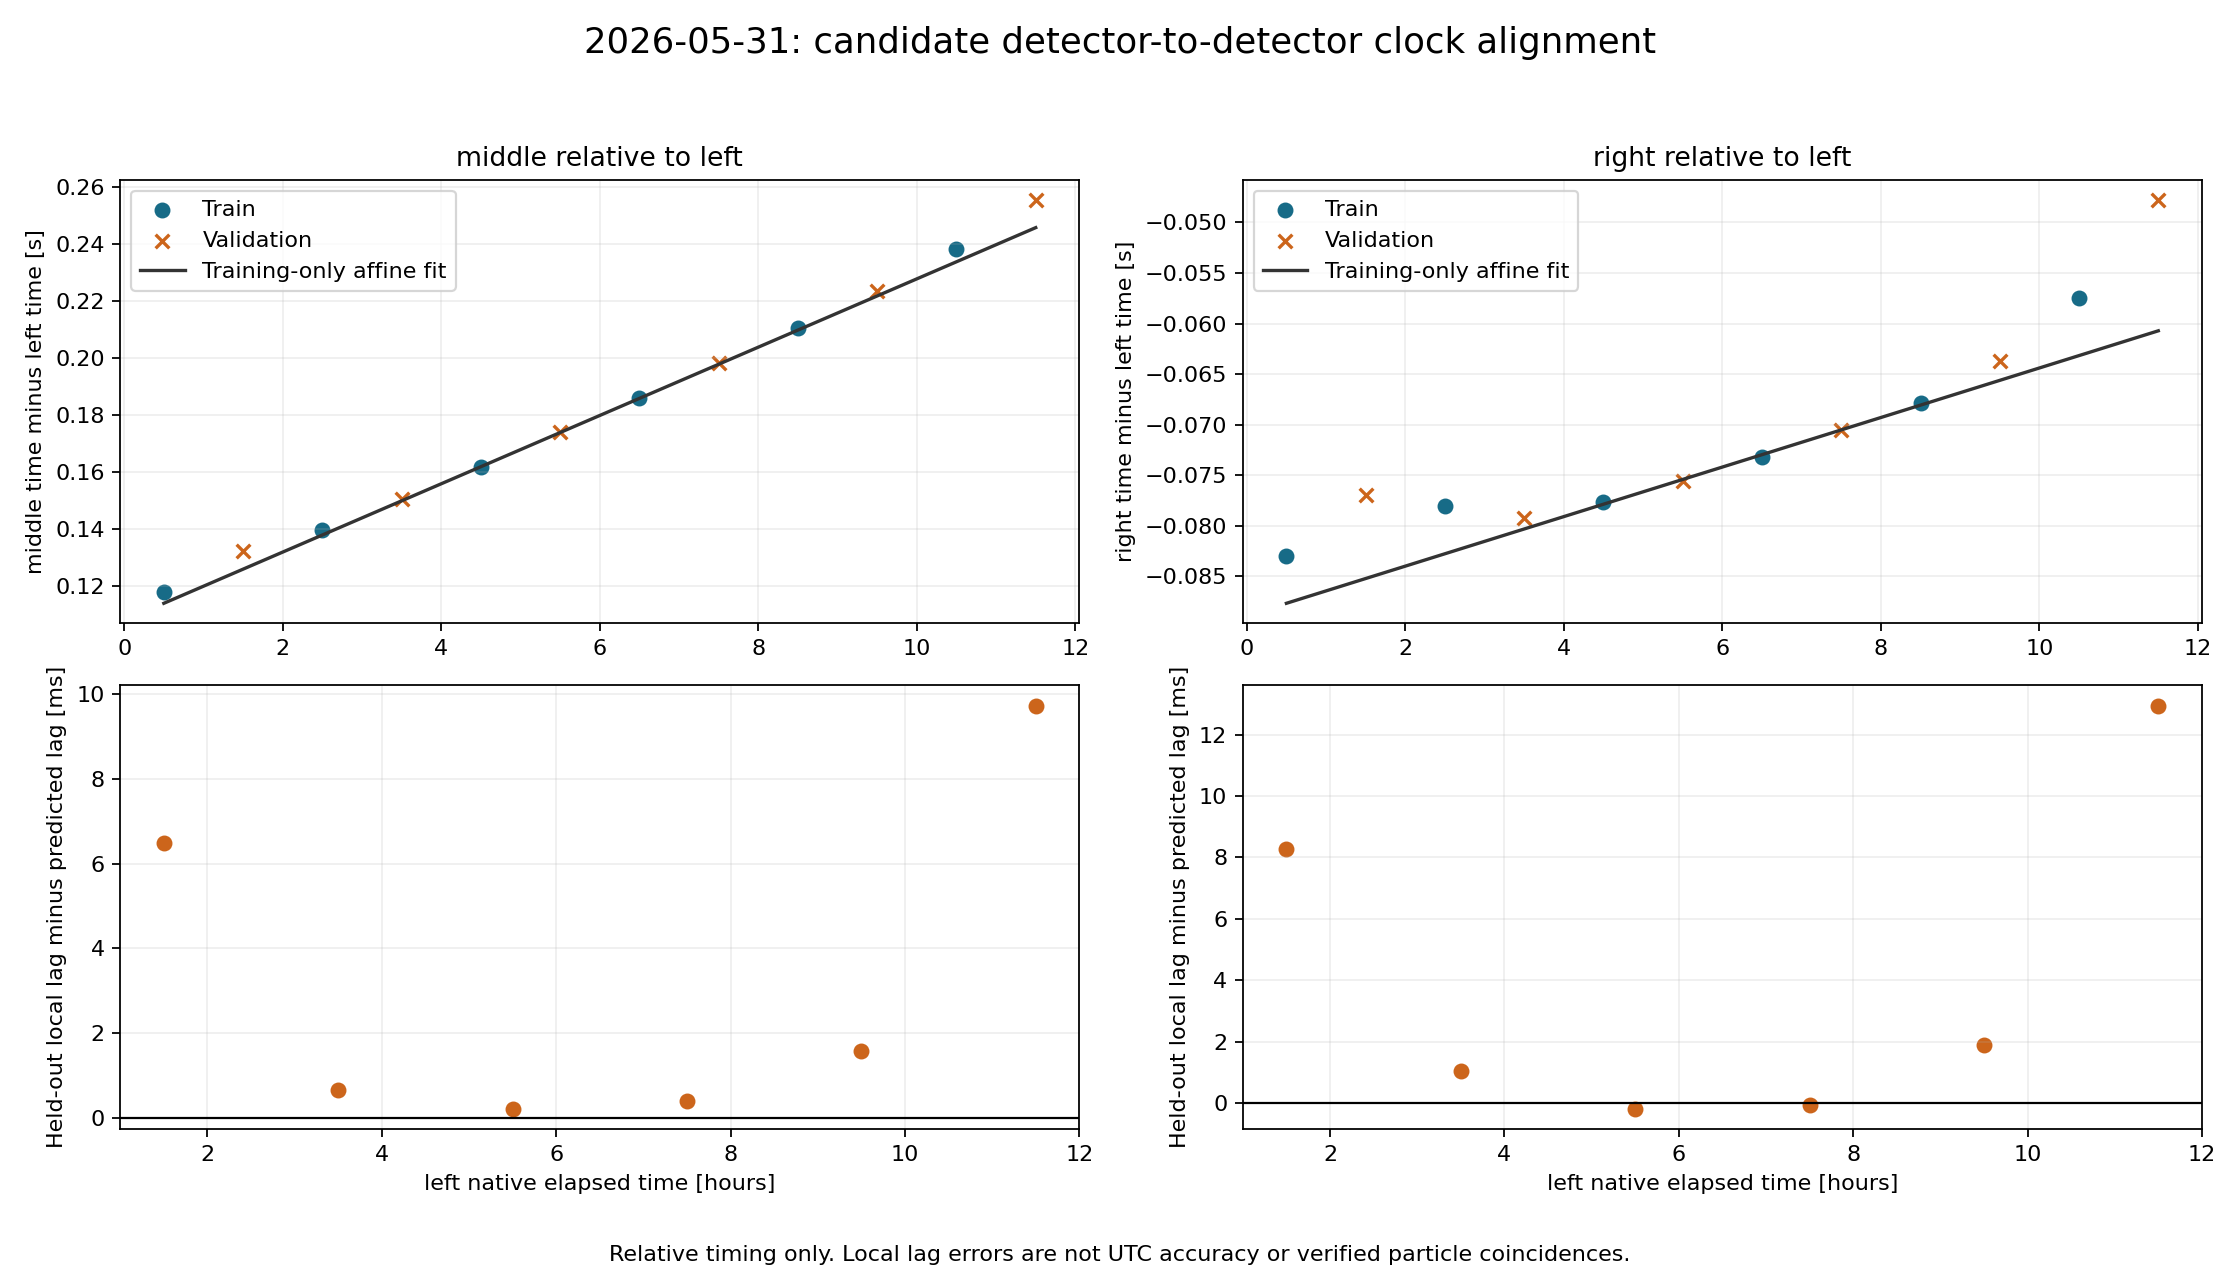

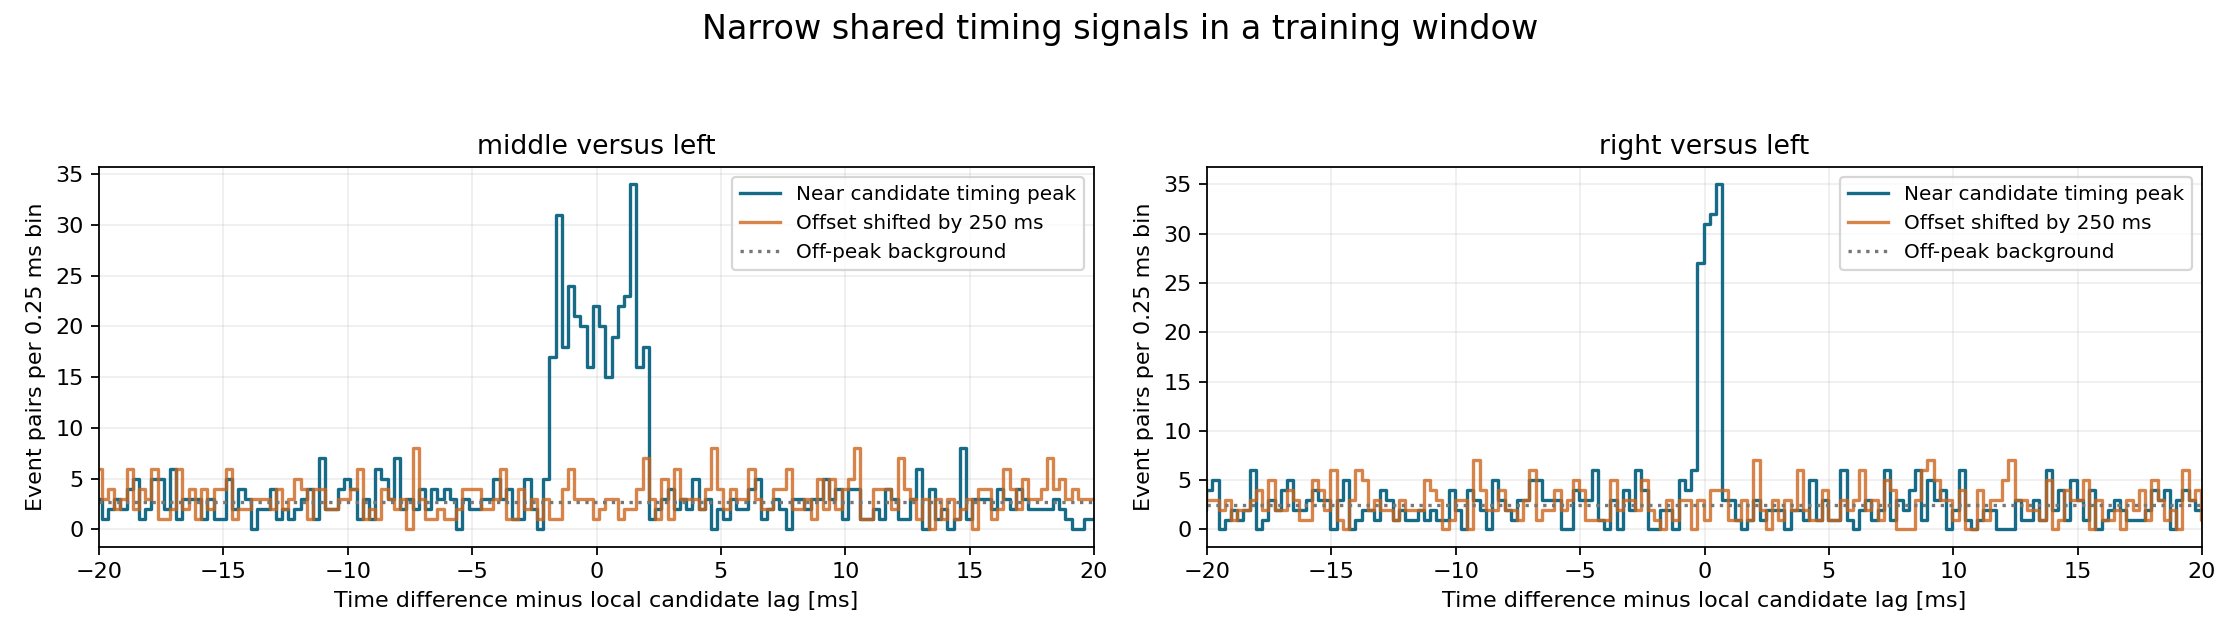

,filename,sha256,rows,status,rollover_period_s_candidate,rollover_candidates,timer_span_hours_candidate,rtc_daily_unwrap_span_hours_candidate,recorded_dates,rtc_backward_steps,rtc_signed_midnight_crossings,utc_verified,correction_applied
0,AHD011 copy.csv,0f31086f97b9e6e3f0760d3351baef40174867f35003eb...,92791,recording_coverage_unresolved_not_aligned,4294.967296,9,11.878487,11.906856,{'5/31/2026': 92791},3274,1,False,False


In [4]:
display(Image(filename=str(RUN_DIR / "clock_alignment.png")))
display(Image(filename=str(RUN_DIR / "timing_signal.png")))
display(pd.DataFrame([report["logger_audit"]]))

## Interpret the result

- `alignment_report.json` stores candidate map coefficients, source hashes, settings, and limits.
- `local_lags.csv` stores the independently measured offsets and shifted-offset controls.
- `validation_metrics.csv` compares a constant offset against offset plus drift.
- `clock_alignment.png` shows drift and held-out local-lag errors.
- `timing_signal.png` shows one training-window timing excess and a deliberately shifted control.

Systematic residuals mean a single straight-line drift correction has limits. Decide the required
timing precision before using a map for event coincidence analysis. Timing excesses may include
correlated electronics; they do not identify particle species or prove individual event identity.
No corrected event files are exported. `align_clocks.map_to_reference(times, model)` returns
candidate times plus a flag marking the span between training centers, without editing inputs.

For May 31: retain its own detector labels, choose windows inside its recording, and refit.
Do not reuse ground-run coefficients or force the logger's 16.8 candidate hours into 193.7 hours.